# T2 — Preço de pratos por imagem

João Vitor R. Almeida e Leonardo M. C. Prado

ResNet-18 congelada e cabeça de regressão. O notebook repete o treinamento com características reais já extraídas; as 250 imagens de teste continuam reservadas.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util

if not Path('src/train.py').exists():
    if not Path('redes-neurais-pratos').exists():
        subprocess.run(['git','clone','https://github.com/metrix0/redes-neurais-pratos.git'],check=True)
    os.chdir('redes-neurais-pratos')
needed = ['torch','torchvision','sklearn','pandas','matplotlib','reportlab']
if any(importlib.util.find_spec(name) is None for name in needed):
    subprocess.run([sys.executable,'-m','pip','install','-q','torch==2.14.1','torchvision==0.29.1',
                    '--index-url','https://download.pytorch.org/whl/cpu'],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements.txt'],check=True)
sys.path.insert(0,str(Path.cwd()))
print('Projeto pronto:', Path.cwd().name)

Projeto pronto: redes-neurais-pratos


resnet_ridge_raw_1 train-group-CV MAE 9.7381
resnet_ridge_raw_10 train-group-CV MAE 8.0939
resnet_ridge_raw_100 train-group-CV MAE 6.4732
resnet_ridge_raw_1000 train-group-CV MAE 5.3804
resnet_ridge_raw_10000 train-group-CV MAE 5.0717
resnet_ridge_log_1 train-group-CV MAE 8.623
resnet_ridge_log_10 train-group-CV MAE 6.7196
resnet_ridge_log_100 train-group-CV MAE 5.4118
resnet_ridge_log_1000 train-group-CV MAE 4.8268
resnet_ridge_log_10000 train-group-CV MAE 4.8652
resnet_trees_leaf2 train-group-CV MAE 5.0337
resnet_trees_leaf8 train-group-CV MAE 4.9512
resnet_trees_leaf20 train-group-CV MAE 4.96
resnet_knn_5 train-group-CV MAE 5.5723
resnet_knn_15 train-group-CV MAE 5.5052
resnet_knn_30 train-group-CV MAE 5.3891
{
  "mean": {
    "mae": 5.548498824478113,
    "r2": -0.10333653310047208,
    "pred_std": 1.7763568394002505e-15,
    "pred_p10_p50_p90": [
      9.70076127819549,
      9.70076127819549,
      9.70076127819549
    ]
  },
  "median": {
    "mae": 6.670785498489425,
    "r2": 

,mae,r2,pred_std,pred_p10_p50_p90
mean,5.548499,-0.103337,0.0,"[9.70076127819549, 9.70076127819549, 9.7007612..."
median,6.670785,-0.415972,0.0,"[7.0, 7.0, 7.0]"
color_ridge,5.69038,-0.094284,3.762781,"[7.780984878540039, 12.575966835021973, 15.466..."
resnet,4.762163,0.025696,3.664257,"[4.92755651473999, 9.74105453491211, 14.962728..."


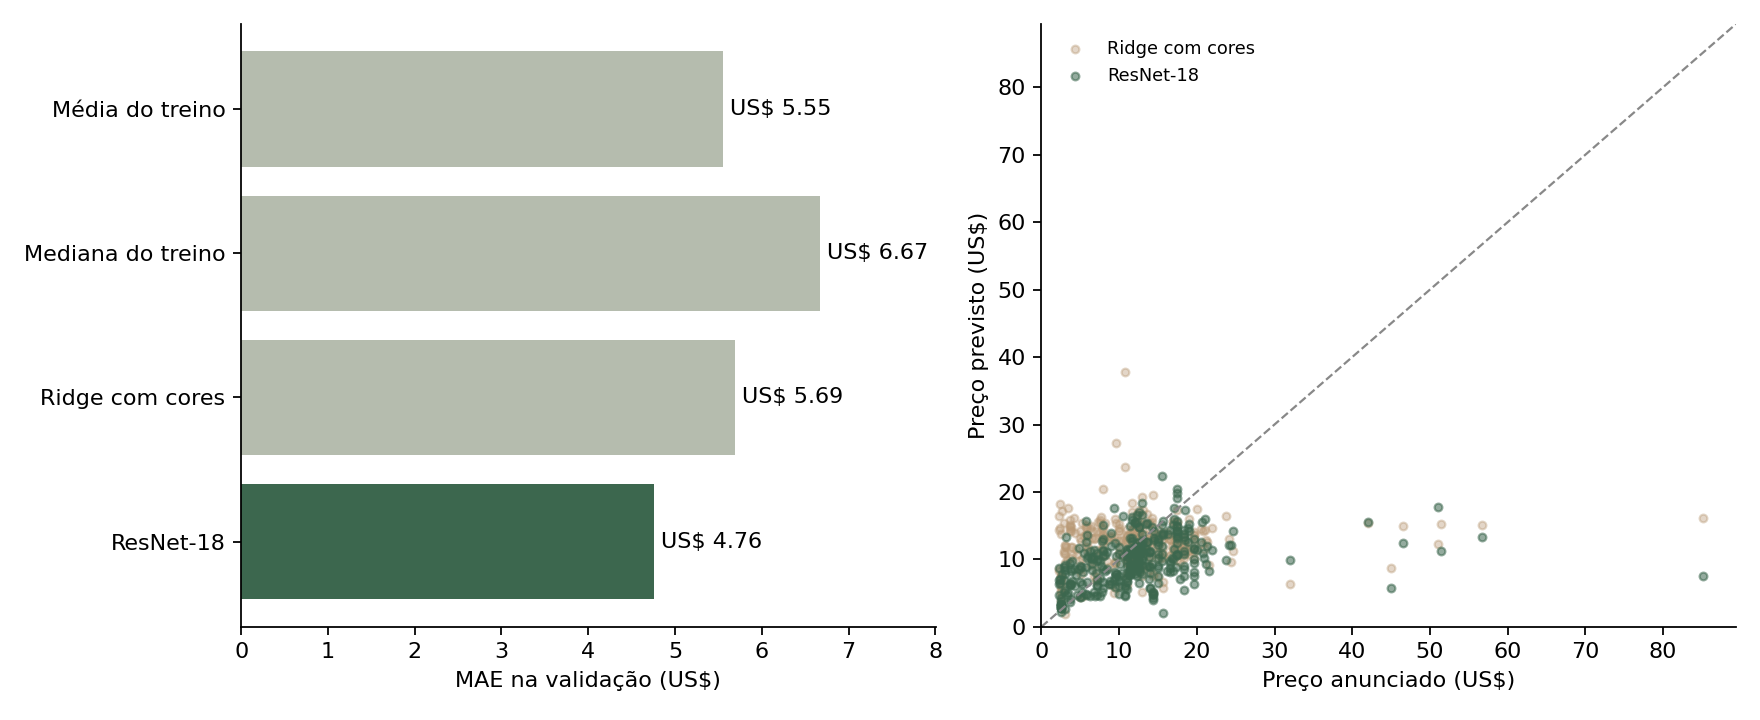

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
print(subprocess.check_output([sys.executable,'src/train.py'],text=True))
print(subprocess.check_output([sys.executable,'src/report.py'],text=True))
results=json.loads(Path('results/comparison.json').read_text())
display(pd.DataFrame(results['validation']).T)
assert results['test_evaluated'] is False
display(Image(filename='results/comparison.png'))

In [3]:
curve=pd.read_csv('results/learning_curve.csv')
display(curve.groupby('fraction')['validation_mae'].agg(['mean','std']))
display(pd.DataFrame(results['bands']))
print('Teste reservado:', results['counts']['reserved_test'], 'imagens')

Teste reservado: 250 imagens


,mean,std
fraction,,
0.25,5.041383,1.768094e-01
0.50,4.894151,8.383683e-02
1.00,4.762163,1.633859e-07


,actual_price_band,n,actual_mean,old_pred_mean,new_pred_mean,old_mae,new_mae
0,0–5,49,3.226327,11.011552,6.126405,7.995049,2.949903
1,5–10,70,7.476286,12.307704,8.854026,5.190323,2.802974
2,10–20,191,14.245393,12.362496,10.915911,3.674699,4.117437
3,20–inf,21,33.189048,12.876282,11.803715,20.312766,21.385334


In [4]:
from src.predict import predict
sample_result=predict(Path('web/pasta.jpg').read_bytes())
print(json.dumps(sample_result,indent=2))

{
  "price": 11.722492218017578,
  "currency": "USD",
  "validation_mae": 4.762163083142744,
  "model": "resnet_ridge_log_1000"
}


## Usar outra foto no Colab

A célula abaixo abre o seletor somente no Colab. As fotos não são acrescentadas ao treino.

In [5]:
try:
    in_colab=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    in_colab=False
if in_colab:
    from google.colab import files
    photos=files.upload()
    for name,raw in photos.items():
        print(name, predict(raw))
else:
    print('Fora do Colab: python -m src.predict caminho/para/foto.jpg')

Fora do Colab: python -m src.predict caminho/para/foto.jpg


## Recalcular as características

Para recuperar as imagens com verificação de hash e executar a ResNet novamente, rode os comandos abaixo no terminal. A disponibilidade das URLs pode mudar.

~~~bash
python src/download_images.py
python src/extract_features.py
python src/train.py
~~~

Os pesos IMAGENET1K_V1 são obtidos pelo Torchvision. Apenas o regressor foi treinado. O erro médio não é um intervalo garantido; itens caros continuam problemáticos.